# Module 2 · Lab 2.4 — Prompt Chaining & Quality Gates
## Healthcare Emergency Triage System
## Agentic Design Pattern #1: Sequential Chain with Confidence-Based Retry

---

### Lab Overview

In this lab we build a **prompt chaining pipeline** for Apollo Hospitals that processes
patient intake forms through a sequential chain of specialised steps, with **quality gates**
to prevent errors from propagating downstream.

| Detail | Value |
|--------|-------|
| **Pattern** | Prompt Chaining + Quality Gate (conditional retry loop) |
| **Domain** | Healthcare Emergency Triage |
| **Model** | `gpt-4.1-mini` (temperature 0.3) |
| **Framework** | LangGraph (StateGraph, conditional edges) |
| **Pipeline Steps** | 4 chained prompts + 1 quality gate |
| **Key Concept** | Each step's output becomes the next step's input -- errors caught early |

---

## 1. Environment Setup

Install the required packages. We use **LangChain v1** and **LangGraph v1** with the
OpenAI integration package.

In [ ]:
# 📦 Packages this notebook needs. On the training VM they are already installed,
# so the install line below stays commented out.
# Running somewhere else (Colab, your own laptop)? Uncomment it and run this cell once.
# !pip install -qU langchain langchain-core langchain-openai langgraph python-dotenv

## 2. API Key Configuration

> **Setup:** Click the key icon in Colab's left sidebar, add `OPENAI_API_KEY`, and toggle
> **Notebook access** ON.

In [ ]:
import os

def load_keys(required):
    """Load API keys from Colab Secrets (on Colab) or a local .env file (elsewhere)."""
    try:
        from google.colab import userdata          # running on Google Colab
        for key_name in required:
            try:
                os.environ[key_name] = userdata.get(key_name)
            except Exception:
                pass                                 # not set in Colab Secrets
        source = "Colab Secrets"
    except ImportError:                              # running locally / non-Colab
        try:
            from dotenv import load_dotenv, find_dotenv
            load_dotenv(find_dotenv(usecwd=True))     # searches cwd upward for a .env
        except ImportError:
            pass
        source = ".env / environment"
    print(f"🔑 Key source: {source}")
    for key_name in required:
        print(f"   {key_name:<22} {'✅' if os.environ.get(key_name) else '❌ MISSING'}")

load_keys(["OPENAI_API_KEY"])

## 3. Imports & LLM Initialisation

We use **one model** throughout this lab -- `gpt-4.1-mini` at temperature 0.3.

In [3]:
# --- Core Python ---
import operator
from typing import TypedDict

# --- LangChain ---
from langchain.chat_models import init_chat_model
from langchain_core.prompts import ChatPromptTemplate

# --- LangGraph ---
from langgraph.graph import StateGraph, START, END

# Initialise the LLM
llm = init_chat_model("openai:gpt-4.1-mini", temperature=0.3)

# Quick smoke test
resp = llm.invoke("Say 'LLM ready' and nothing else.")
print(resp.content)

LLM ready


---

## 4. Business Scenario: Apollo Hospitals Emergency Department

**Apollo Hospitals** is India's largest hospital chain with emergency departments across
4 metro locations handling **500+ patient intake forms daily**. The current manual triage
process has these challenges:

1. **Slow Symptom Extraction (3 min/patient)** -- When a patient arrives, they fill a
   free-text intake form describing their symptoms. A triage nurse must read the form,
   mentally extract the key symptoms, and categorise the chief complaint. During peak
   hours (8--11 PM), 60+ patients arrive per hour and 3 nurses cannot keep up.

2. **Inconsistent Urgency Assessment (2 min/patient)** -- Different nurses assign
   different urgency levels to the same symptoms. A "chest pain with shortness of
   breath" might be rated "urgent" by one nurse and "emergency" by another. There is
   no standardised confidence scoring -- nurses rely on intuition and experience level
   varies.

3. **Department Misrouting (15% error rate)** -- After urgency assessment, the nurse
   recommends a department. Errors are common -- a patient with neurological symptoms
   (severe headache + vision changes) might be routed to General Medicine instead of
   Neurology, causing a 30-minute delay in specialist evaluation.

4. **Incomplete Summaries (5 min/patient)** -- The triage summary written for the
   attending physician is often incomplete. Key details like medication allergies,
   recent surgeries, or concurrent conditions are missed because the nurse is rushed.

**Total manual process: ~12 minutes per patient. During peak hours, wait times exceed 45 minutes.**

### Our Solution: 4-Step Prompt Chain with Quality Gate

| Step | Name | What It Does |
|------|------|-------------|
| 1 | **Symptom Extraction** | Parse free-text intake form into structured symptoms list |
| 2 | **Urgency Assessment** | Assess urgency level (emergency/urgent/standard/routine) with confidence |
| Gate | **Quality Gate** | If confidence < 0.7, loop back to Step 2 with more context (max 2 retries) |
| 3 | **Department Recommendation** | Route to correct department based on symptoms + urgency |
| 4 | **Summary Generation** | Compile physician-ready triage summary |

```
START --> extract_symptoms --> assess_urgency --> quality_gate
                                                    |
                                     (confidence >= 0.7)
                                                    v
                                         recommend_department --> generate_summary --> END
                                                    ^
                              (confidence < 0.7 AND retry < 2)
                                                    |
                                              assess_urgency (retry)
```

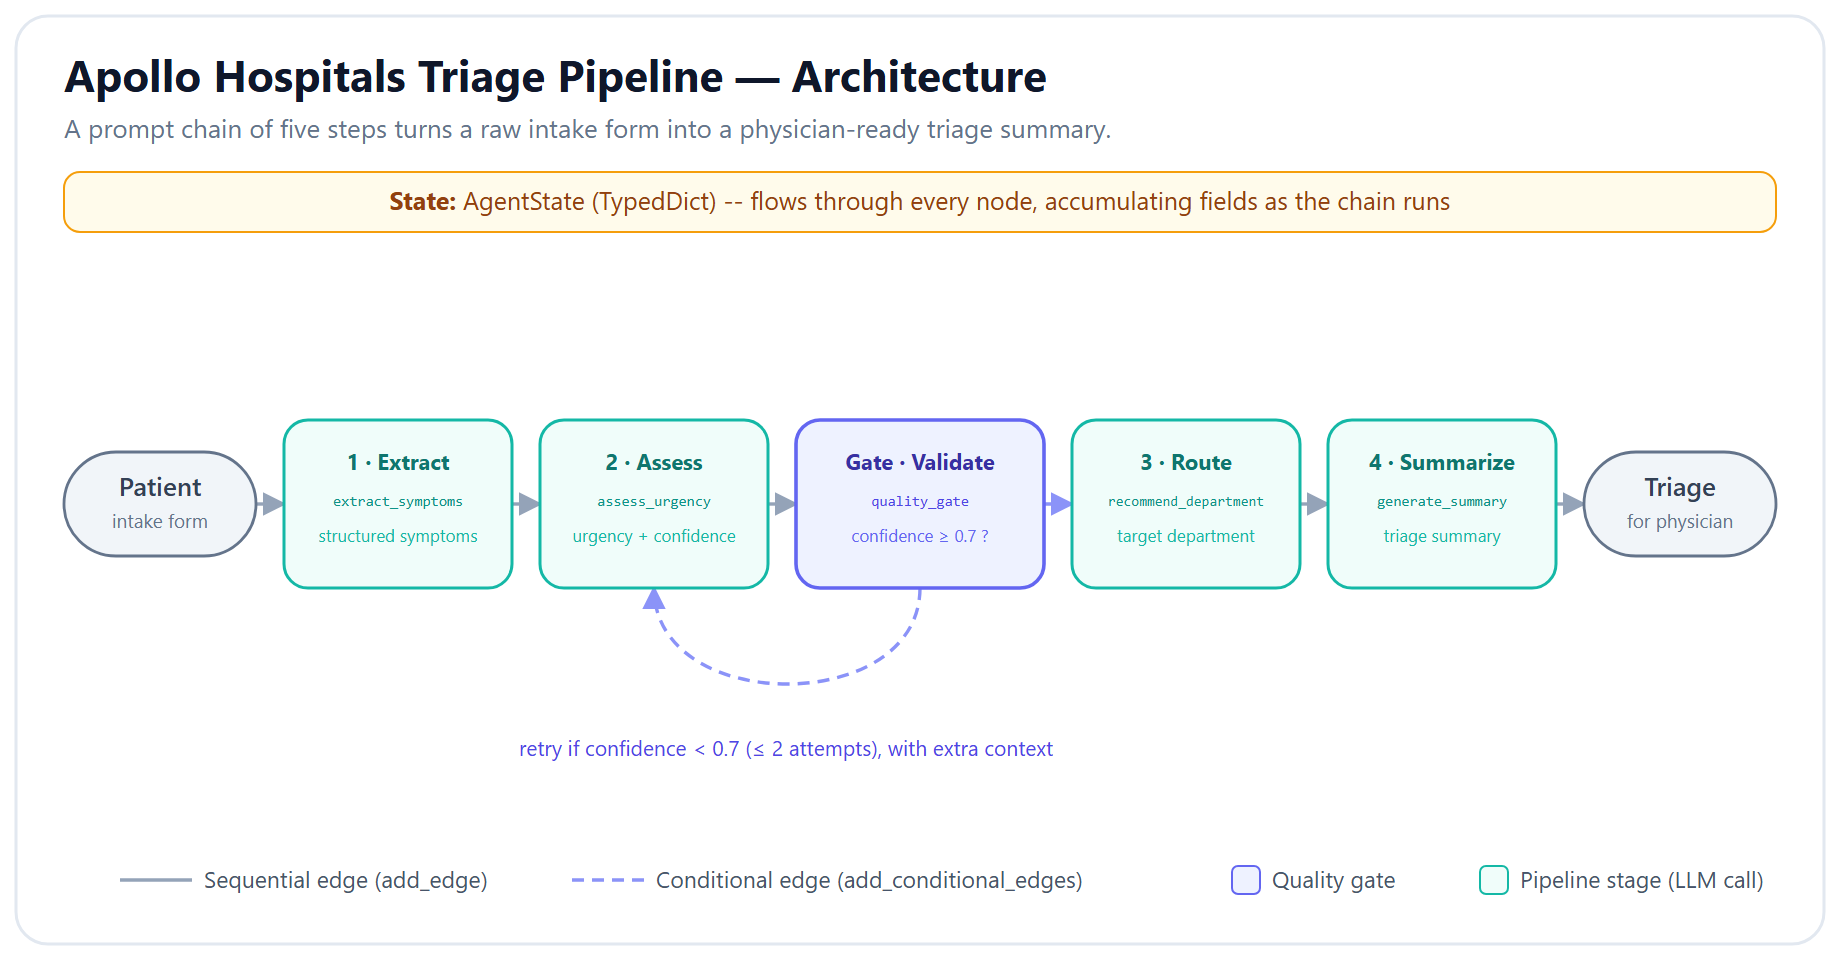

**Figure — Emergency-triage pipeline architecture.** A patient intake form moves through five chained steps — `extract_symptoms`, `assess_urgency`, `quality_gate`, `recommend_department`, `generate_summary` — with the gate able to loop back for a retry before the final triage summary is produced.

## 5. Define the Agent State

A single `AgentState` carries data through all pipeline steps.

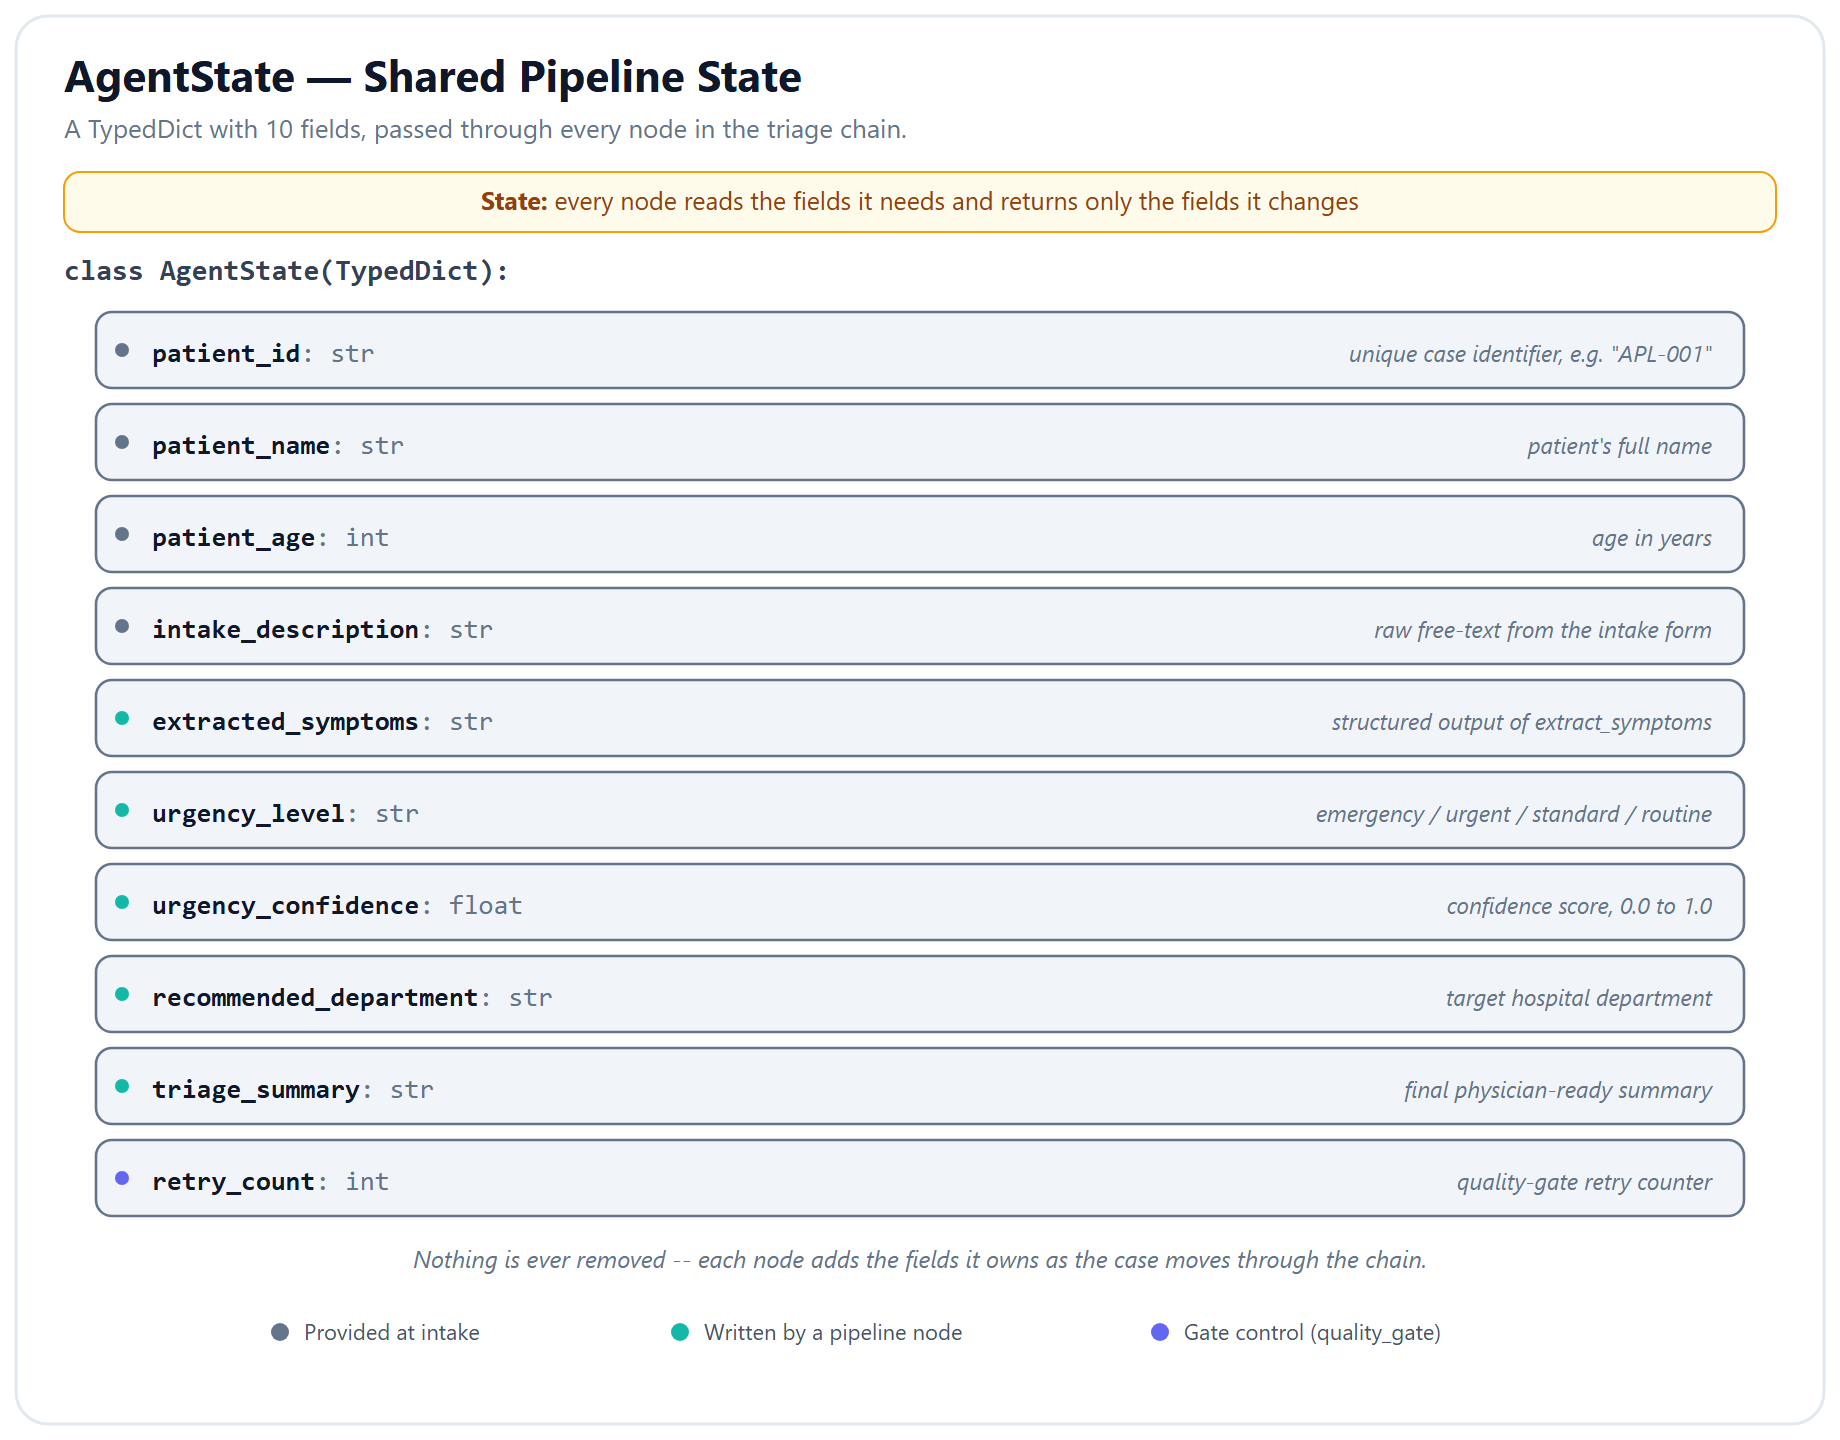

**Figure — AgentState schema.** The graph's shared state is a `TypedDict` with ten fields — four supplied at intake, five written progressively by the pipeline nodes, and `retry_count` for the quality gate — and nothing already written is ever removed.

In [4]:
# ------------------------------------------------------------------
# Agent State
# ------------------------------------------------------------------

class AgentState(TypedDict):
    """State that flows through the entire triage pipeline."""
    patient_id: str
    patient_name: str
    patient_age: int
    intake_description: str        # Free-text from patient intake form
    extracted_symptoms: str         # Structured symptoms from Step 1
    urgency_level: str              # emergency, urgent, standard, routine
    urgency_confidence: float       # 0.0 to 1.0
    recommended_department: str     # Target department
    triage_summary: str             # Final physician-ready summary
    retry_count: int                # Quality gate retry counter

print("AgentState defined.")
print("Fields:", list(AgentState.__annotations__.keys()))

AgentState defined.
Fields: ['patient_id', 'patient_name', 'patient_age', 'intake_description', 'extracted_symptoms', 'urgency_level', 'urgency_confidence', 'recommended_department', 'triage_summary', 'retry_count']


## 6. Patient Intake Data (10 Cases)

Ten diverse patient intake forms -- all inline, no external files.
Cases 9 and 10 are deliberately **ambiguous/vague** to trigger the quality gate.

In [5]:
# ------------------------------------------------------------------
# Synthetic patient intake data -- all inline
# ------------------------------------------------------------------

PATIENTS = [
    {
        "patient_id": "APL-001",
        "patient_name": "Rajesh Kumar",
        "patient_age": 58,
        "intake_description": (
            "I have been having severe chest pain for the last 30 minutes. It started "
            "suddenly while I was climbing stairs. The pain radiates to my left arm and "
            "jaw. I am also feeling very short of breath and sweating profusely. I have "
            "a history of high blood pressure and high cholesterol. I take Amlodipine 5mg "
            "and Atorvastatin 20mg daily. I am diabetic as well."
        ),
    },
    {
        "patient_id": "APL-002",
        "patient_name": "Priya Sharma",
        "patient_age": 32,
        "intake_description": (
            "I fell off my scooter about an hour ago and landed on my right arm. My "
            "forearm is swollen and I cannot move my wrist at all. There is a visible "
            "deformity near the wrist. The pain is 9 out of 10. No head injury, I was "
            "wearing a helmet. No other injuries. No allergies to any medications."
        ),
    },
    {
        "patient_id": "APL-003",
        "patient_name": "Arjun Mehra",
        "patient_age": 4,
        "intake_description": (
            "My son has had a fever of 103 degrees Fahrenheit since yesterday evening. "
            "He is very irritable and crying constantly. He has not eaten anything since "
            "morning. There is a rash on his chest and back that appeared a few hours "
            "ago. He had his last vaccination 2 months ago. No known allergies. He weighs "
            "about 16 kg."
        ),
    },
    {
        "patient_id": "APL-004",
        "patient_name": "Sunita Reddy",
        "patient_age": 45,
        "intake_description": (
            "I have the worst headache of my life. It came on suddenly about 2 hours ago "
            "like a thunderclap. My vision is blurred and I see spots. I feel nauseous "
            "and the light is bothering my eyes. I also feel stiffness in my neck. I have "
            "no history of migraines. I take no regular medications. My mother had a "
            "brain aneurysm."
        ),
    },
    {
        "patient_id": "APL-005",
        "patient_name": "Mohammed Farooq",
        "patient_age": 38,
        "intake_description": (
            "I have been having stomach pain since last night after eating dinner at a "
            "restaurant. The pain is in the upper abdomen, comes and goes in waves. I "
            "have vomited 3 times and feel nauseous. I also have loose motions since "
            "morning. No fever. No blood in vomit or stool. I am not on any medications. "
            "No known food allergies but I ate shellfish for the first time."
        ),
    },
    {
        "patient_id": "APL-006",
        "patient_name": "Kavitha Nair",
        "patient_age": 27,
        "intake_description": (
            "I cut my left hand deeply while chopping vegetables about 45 minutes ago. "
            "The cut is on my palm, about 3 inches long, and it will not stop bleeding "
            "even with pressure. I can see some tissue inside. I can move all my fingers "
            "but the ring finger feels numb. Last tetanus shot was 8 years ago. No "
            "allergies. No other medical conditions."
        ),
    },
    {
        "patient_id": "APL-007",
        "patient_name": "Vikram Patel",
        "patient_age": 52,
        "intake_description": (
            "I am here for my 2-week post-surgery follow-up. I had arthroscopic knee "
            "surgery on my right knee 14 days ago at this hospital. The surgical wounds "
            "are healing well, no redness or discharge. I can bend my knee to about 90 "
            "degrees. Mild pain when walking, about 3 out of 10. I am taking Paracetamol "
            "500mg as needed. Doing my physiotherapy exercises twice daily as instructed."
        ),
    },
    {
        "patient_id": "APL-008",
        "patient_name": "Deepa Krishnan",
        "patient_age": 22,
        "intake_description": (
            "I twisted my right ankle while playing cricket this morning. It swelled up "
            "immediately and I could not put weight on it. I have been applying ice. The "
            "pain is about 6 out of 10. I can wiggle my toes. No cracking sound when it "
            "happened. No previous ankle injuries. No medications. No allergies."
        ),
    },
    {
        "patient_id": "APL-009",
        "patient_name": "Anita Deshmukh",
        "patient_age": 41,
        "intake_description": (
            "I have been feeling very tired for the past 2 weeks. I also get dizzy when "
            "I stand up quickly. Sometimes I feel my heart beating fast for no reason. "
            "I have not had any fever. My appetite is normal but I feel weak. I have been "
            "sleeping 8 hours but still feel exhausted. No recent travel. I am a "
            "vegetarian. No known medical conditions."
        ),
    },
    {
        "patient_id": "APL-010",
        "patient_name": "Ravi Shankar",
        "patient_age": 35,
        "intake_description": (
            "I am not feeling well. Everything hurts. I have been feeling off for a few "
            "days now. Sometimes I feel hot, sometimes cold. My body aches all over. I "
            "am just not myself. I cannot really describe what is wrong. I just feel "
            "really bad and want someone to check me out."
        ),
    },
]

print(f"Loaded {len(PATIENTS)} patient intake forms.")
for p in PATIENTS:
    print(f"  {p['patient_id']}: {p['patient_name']}, age {p['patient_age']}")

Loaded 10 patient intake forms.
  APL-001: Rajesh Kumar, age 58
  APL-002: Priya Sharma, age 32
  APL-003: Arjun Mehra, age 4
  APL-004: Sunita Reddy, age 45
  APL-005: Mohammed Farooq, age 38
  APL-006: Kavitha Nair, age 27
  APL-007: Vikram Patel, age 52
  APL-008: Deepa Krishnan, age 22
  APL-009: Anita Deshmukh, age 41
  APL-010: Ravi Shankar, age 35


---

## 7. Node Functions

We will define **5 node functions** for our graph. Each is a flat Python function that
receives `state` (an `AgentState` dict) and returns a dict of updated fields.

| # | Node Function | Purpose |
|---|---------------|--------|
| 1 | `extract_symptoms` | Parse free-text intake into structured symptoms + chief complaint |
| 2 | `assess_urgency` | Evaluate symptoms for urgency level + confidence score |
| 3 | `quality_gate` | Check confidence threshold; route forward or retry |
| 4 | `recommend_department` | Map urgency + symptoms to hospital department |
| 5 | `generate_summary` | Compile physician-ready triage summary |

### 7a. Node 1: `extract_symptoms`

Parses the free-text intake form into a structured list of symptoms and identifies
the chief complaint.

In [6]:
# ------------------------------------------------------------------
# Node 1: extract_symptoms
# ------------------------------------------------------------------

def extract_symptoms(state: AgentState) -> dict:
    """Parse free-text intake form into structured symptoms list."""
    prompt = ChatPromptTemplate.from_template(
        "You are a triage nurse at Apollo Hospitals. A patient has filled out an intake form.\n"
        "Extract the key medical information in a structured format.\n\n"
        "Patient: {patient_name}, Age: {patient_age}\n"
        "Intake Form:\n{intake_description}\n\n"
        "Provide your response in EXACTLY this format:\n"
        "CHIEF COMPLAINT: [one-line summary of the main problem]\n"
        "SYMPTOMS:\n- [symptom 1]\n- [symptom 2]\n- [etc.]\n"
        "MEDICAL HISTORY: [relevant history or 'None reported']\n"
        "CURRENT MEDICATIONS: [medications or 'None reported']\n"
        "ALLERGIES: [allergies or 'None reported']"
    )
    chain = prompt | llm
    response = chain.invoke({
        "patient_name": state["patient_name"],
        "patient_age": state["patient_age"],
        "intake_description": state["intake_description"],
    })
    return {"extracted_symptoms": response.content}

In [8]:
# ------------------------------------------------------------------
# Test Node 1 individually with Patient APL-001
# ------------------------------------------------------------------

test_state_1 = {
    "patient_id": PATIENTS[0]["patient_id"],
    "patient_name": PATIENTS[0]["patient_name"],
    "patient_age": PATIENTS[0]["patient_age"],
    "intake_description": PATIENTS[0]["intake_description"],
    "extracted_symptoms": "",
    "urgency_level": "",
    "urgency_confidence": 0.0,
    "recommended_department": "",
    "triage_summary": "",
    "retry_count": 0,
}

result_1 = extract_symptoms(test_state_1)
print("=== Node 1 Test: extract_symptoms ===")
print(f"Patient: {PATIENTS[0]['patient_name']}")
print()
print(result_1["extracted_symptoms"])

=== Node 1 Test: extract_symptoms ===
Patient: Rajesh Kumar

CHIEF COMPLAINT: Severe chest pain for the last 30 minutes  
SYMPTOMS:  
- Severe chest pain radiating to left arm and jaw  
- Sudden onset during physical activity (climbing stairs)  
- Shortness of breath  
- Profuse sweating  
MEDICAL HISTORY: High blood pressure, high cholesterol, diabetes  
CURRENT MEDICATIONS: Amlodipine 5mg daily, Atorvastatin 20mg daily  
ALLERGIES: None reported


### 7b. Node 2: `assess_urgency`

Evaluates the extracted symptoms to determine urgency level and a confidence score.
On retry (retry_count > 0), extra context is added to help the LLM decide.

In [9]:
# ------------------------------------------------------------------
# Node 2: assess_urgency
# ------------------------------------------------------------------

def assess_urgency(state: AgentState) -> dict:
    """Assess urgency level with confidence score. Adds context on retries."""
    retry_context = ""
    if state["retry_count"] > 0:
        retry_context = (
            "\n\nIMPORTANT: Your previous assessment had LOW confidence. This is retry "
            f"#{state['retry_count']}. Please consider:\n"
            "- Look for subtle red flags (e.g., age-related risks, family history)\n"
            "- Consider worst-case differential diagnoses\n"
            "- If symptoms are vague, lean towards a HIGHER urgency to be safe\n"
            "- Provide a clear justification for your confidence score"
        )

    prompt = ChatPromptTemplate.from_template(
        "You are a senior triage physician at Apollo Hospitals.\n"
        "Based on the extracted symptoms below, assess the urgency level.\n\n"
        "Patient: {patient_name}, Age: {patient_age}\n"
        "Extracted Symptoms:\n{extracted_symptoms}\n"
        "{retry_context}\n\n"
        "Respond in EXACTLY this format (no extra text):\n"
        "URGENCY: [emergency|urgent|standard|routine]\n"
        "CONFIDENCE: [0.0 to 1.0]\n"
        "REASONING: [one paragraph explaining your assessment]"
    )
    chain = prompt | llm
    response = chain.invoke({
        "patient_name": state["patient_name"],
        "patient_age": state["patient_age"],
        "extracted_symptoms": state["extracted_symptoms"],
        "retry_context": retry_context,
    })

    # Parse urgency and confidence from the LLM response
    content = response.content
    urgency = "standard"  # default
    confidence = 0.5      # default

    for line in content.split("\n"):
        line_lower = line.strip().lower()
        if line_lower.startswith("urgency:"):
            raw = line_lower.split(":", 1)[1].strip()
            if raw in ["emergency", "urgent", "standard", "routine"]:
                urgency = raw
        if line_lower.startswith("confidence:"):
            try:
                confidence = float(line_lower.split(":", 1)[1].strip())
            except ValueError:
                confidence = 0.5

    return {
        "urgency_level": urgency,
        "urgency_confidence": confidence,
    }

In [10]:
# ------------------------------------------------------------------
# Test Node 2 individually -- feed it output from Node 1
# ------------------------------------------------------------------

test_state_2 = {**test_state_1, **result_1}  # merge Node 1 output
result_2 = assess_urgency(test_state_2)

print("=== Node 2 Test: assess_urgency ===")
print(f"Patient: {PATIENTS[0]['patient_name']}")
print(f"Urgency Level: {result_2['urgency_level']}")
print(f"Confidence: {result_2['urgency_confidence']}")

=== Node 2 Test: assess_urgency ===
Patient: Rajesh Kumar
Urgency Level: emergency
Confidence: 0.95


### 7c. Node 3: `quality_gate`

This is the **quality gate** -- a pure Python function (no LLM call). It checks if
the urgency confidence meets the threshold (>= 0.7). Returns the routing decision.

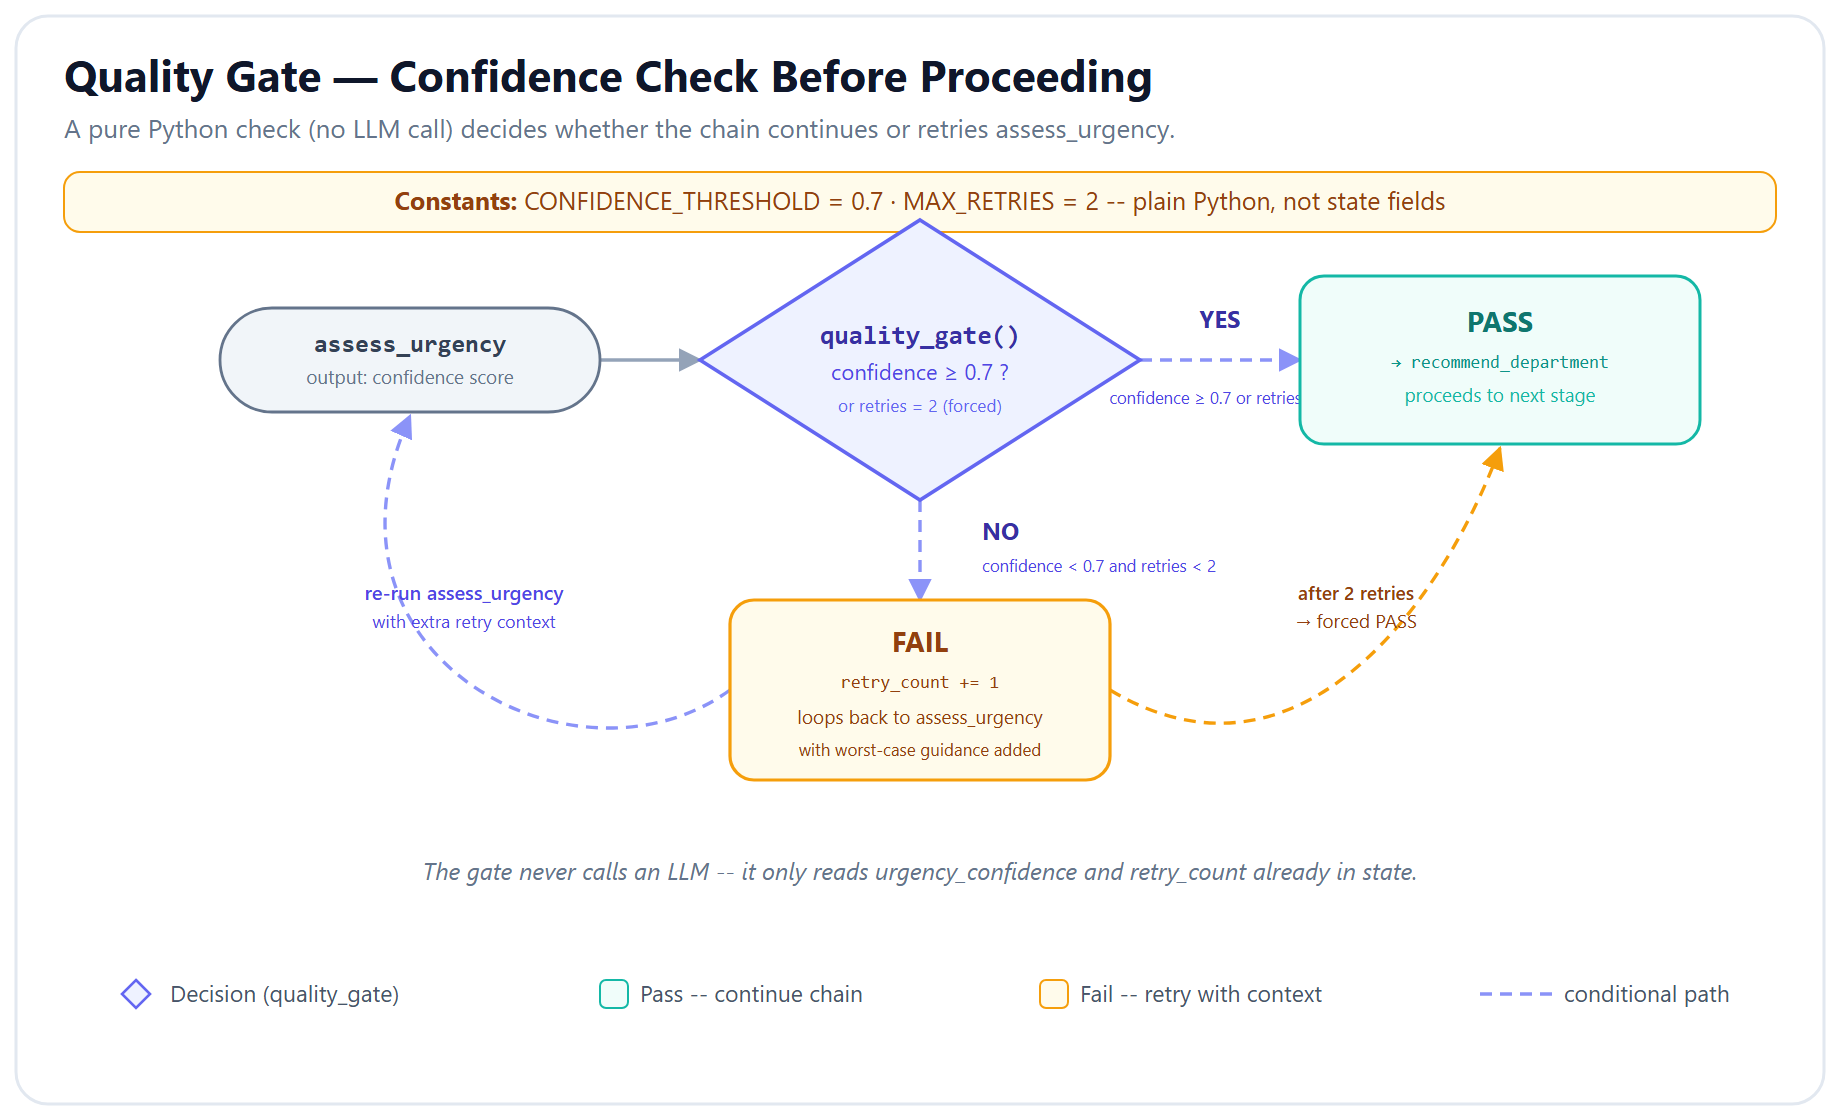

**Figure — Quality gate confidence check.** `quality_gate` is a pure Python function — no LLM call — that reads `urgency_confidence` and `retry_count`: pass at 0.7+ confidence (or after 2 retries), otherwise fail and retry `assess_urgency` with extra context.

In [11]:
# ------------------------------------------------------------------
# Node 3: quality_gate
# ------------------------------------------------------------------

CONFIDENCE_THRESHOLD = 0.7
MAX_RETRIES = 2

def quality_gate(state: AgentState) -> dict:
    """Check urgency confidence. Increment retry count if below threshold."""
    confidence = state["urgency_confidence"]
    retries = state["retry_count"]

    if confidence >= CONFIDENCE_THRESHOLD:
        print(f"  [GATE] PASS -- confidence {confidence:.2f} >= {CONFIDENCE_THRESHOLD}")
    elif retries >= MAX_RETRIES:
        print(f"  [GATE] PASS (max retries reached) -- confidence {confidence:.2f}, retries {retries}")
    else:
        print(f"  [GATE] FAIL -- confidence {confidence:.2f} < {CONFIDENCE_THRESHOLD}, retry #{retries + 1}")
        return {"retry_count": retries + 1}

    return {}


def quality_gate_router(state: AgentState) -> str:
    """Routing function for the conditional edge after quality_gate."""
    confidence = state["urgency_confidence"]
    retries = state["retry_count"]

    if confidence >= CONFIDENCE_THRESHOLD:
        return "recommend_department"
    elif retries >= MAX_RETRIES:
        return "recommend_department"
    else:
        return "assess_urgency"

In [12]:
# ------------------------------------------------------------------
# Test Node 3 individually -- high confidence (should pass)
# ------------------------------------------------------------------

test_state_3_pass = {**test_state_2, **result_2}
print("=== Node 3 Test: quality_gate (high confidence) ===")
result_3 = quality_gate(test_state_3_pass)
print(f"Updated state: {result_3}")
print(f"Router decision: {quality_gate_router(test_state_3_pass)}")
print()

# Test with low confidence (should fail and retry)
test_state_3_fail = {**test_state_3_pass, "urgency_confidence": 0.4, "retry_count": 0}
print("=== Node 3 Test: quality_gate (low confidence) ===")
result_3b = quality_gate(test_state_3_fail)
print(f"Updated state: {result_3b}")
print(f"Router decision: {quality_gate_router({**test_state_3_fail, **result_3b})}")

=== Node 3 Test: quality_gate (high confidence) ===
  [GATE] PASS -- confidence 0.95 >= 0.7
Updated state: {}
Router decision: recommend_department

=== Node 3 Test: quality_gate (low confidence) ===
  [GATE] FAIL -- confidence 0.40 < 0.7, retry #1
Updated state: {'retry_count': 1}
Router decision: assess_urgency


### 7d. Node 4: `recommend_department`

Maps urgency level and symptoms to the appropriate hospital department.

In [13]:
# ------------------------------------------------------------------
# Node 4: recommend_department
# ------------------------------------------------------------------

def recommend_department(state: AgentState) -> dict:
    """Route patient to the correct hospital department."""
    prompt = ChatPromptTemplate.from_template(
        "You are the department routing coordinator at Apollo Hospitals.\n"
        "Based on the patient's symptoms and urgency level, recommend the correct department.\n\n"
        "Patient: {patient_name}, Age: {patient_age}\n"
        "Extracted Symptoms:\n{extracted_symptoms}\n"
        "Urgency Level: {urgency_level}\n\n"
        "Available Departments:\n"
        "- Emergency (for life-threatening conditions requiring immediate intervention)\n"
        "- Cardiology (heart-related conditions)\n"
        "- Orthopedics (bone, joint, and musculoskeletal injuries)\n"
        "- Neurology (brain, spine, and nervous system conditions)\n"
        "- General Medicine (general health concerns, infections, undiagnosed conditions)\n"
        "- Pediatrics (children under 12 years)\n"
        "- Gastroenterology (digestive system and abdominal conditions)\n\n"
        "Respond in EXACTLY this format:\n"
        "DEPARTMENT: [department name]\n"
        "REASONING: [one sentence explaining why this department]"
    )
    chain = prompt | llm
    response = chain.invoke({
        "patient_name": state["patient_name"],
        "patient_age": state["patient_age"],
        "extracted_symptoms": state["extracted_symptoms"],
        "urgency_level": state["urgency_level"],
    })

    # Parse department from response
    content = response.content
    department = "General Medicine"  # default fallback
    for line in content.split("\n"):
        if line.strip().upper().startswith("DEPARTMENT:"):
            department = line.split(":", 1)[1].strip()
            break

    return {"recommended_department": department}

In [14]:
# ------------------------------------------------------------------
# Test Node 4 individually
# ------------------------------------------------------------------

test_state_4 = {**test_state_3_pass, **result_2}
result_4 = recommend_department(test_state_4)

print("=== Node 4 Test: recommend_department ===")
print(f"Patient: {PATIENTS[0]['patient_name']}")
print(f"Urgency: {test_state_4['urgency_level']}")
print(f"Recommended Department: {result_4['recommended_department']}")

=== Node 4 Test: recommend_department ===
Patient: Rajesh Kumar
Urgency: emergency
Recommended Department: Emergency


### 7e. Node 5: `generate_summary`

Compiles all collected information into a physician-ready triage summary.

In [15]:
# ------------------------------------------------------------------
# Node 5: generate_summary
# ------------------------------------------------------------------

def generate_summary(state: AgentState) -> dict:
    """Generate a physician-ready triage summary."""
    prompt = ChatPromptTemplate.from_template(
        "You are preparing a triage summary for the attending physician at Apollo Hospitals.\n"
        "Compile a concise, professional summary using the information below.\n\n"
        "Patient ID: {patient_id}\n"
        "Patient: {patient_name}, Age: {patient_age}\n"
        "Extracted Symptoms:\n{extracted_symptoms}\n"
        "Urgency Level: {urgency_level} (confidence: {urgency_confidence})\n"
        "Recommended Department: {recommended_department}\n\n"
        "Write a triage summary in this format:\n"
        "=== TRIAGE SUMMARY ===\n"
        "Patient: [name], [age] years\n"
        "ID: [patient_id]\n"
        "Chief Complaint: [one line]\n"
        "Key Findings: [bullet points]\n"
        "Urgency: [level] | Department: [department]\n"
        "Recommended Immediate Actions: [bullet points]\n"
        "Alerts: [allergies, medications, or risk factors the physician must know]"
    )
    chain = prompt | llm
    response = chain.invoke({
        "patient_id": state["patient_id"],
        "patient_name": state["patient_name"],
        "patient_age": state["patient_age"],
        "extracted_symptoms": state["extracted_symptoms"],
        "urgency_level": state["urgency_level"],
        "urgency_confidence": state["urgency_confidence"],
        "recommended_department": state["recommended_department"],
    })
    return {"triage_summary": response.content}

In [16]:
# ------------------------------------------------------------------
# Test Node 5 individually
# ------------------------------------------------------------------

test_state_5 = {**test_state_4, **result_4}
result_5 = generate_summary(test_state_5)

print("=== Node 5 Test: generate_summary ===")
print(result_5["triage_summary"])

=== Node 5 Test: generate_summary ===
=== TRIAGE SUMMARY ===  
Patient: Rajesh Kumar, 58 years  
ID: APL-001  
Chief Complaint: Severe chest pain for the last 30 minutes  
Key Findings:  
- Severe chest pain radiating to left arm and jaw  
- Sudden onset during physical activity (climbing stairs)  
- Shortness of breath  
- Profuse sweating  
- History of hypertension, hypercholesterolemia, and diabetes  
Urgency: Emergency | Department: Emergency  
Recommended Immediate Actions:  
- Immediate cardiac evaluation including ECG and cardiac enzymes  
- Administer oxygen as needed  
- Establish IV access and prepare for possible advanced cardiac life support  
- Monitor vital signs continuously  
- Prepare for urgent cardiology consultation  
Alerts: No reported allergies; current medications include Amlodipine 5mg daily and Atorvastatin 20mg daily; significant cardiovascular risk factors present


---

## 8. Build the LangGraph

Wire up the nodes into a `StateGraph` with a conditional edge for the quality gate retry loop.

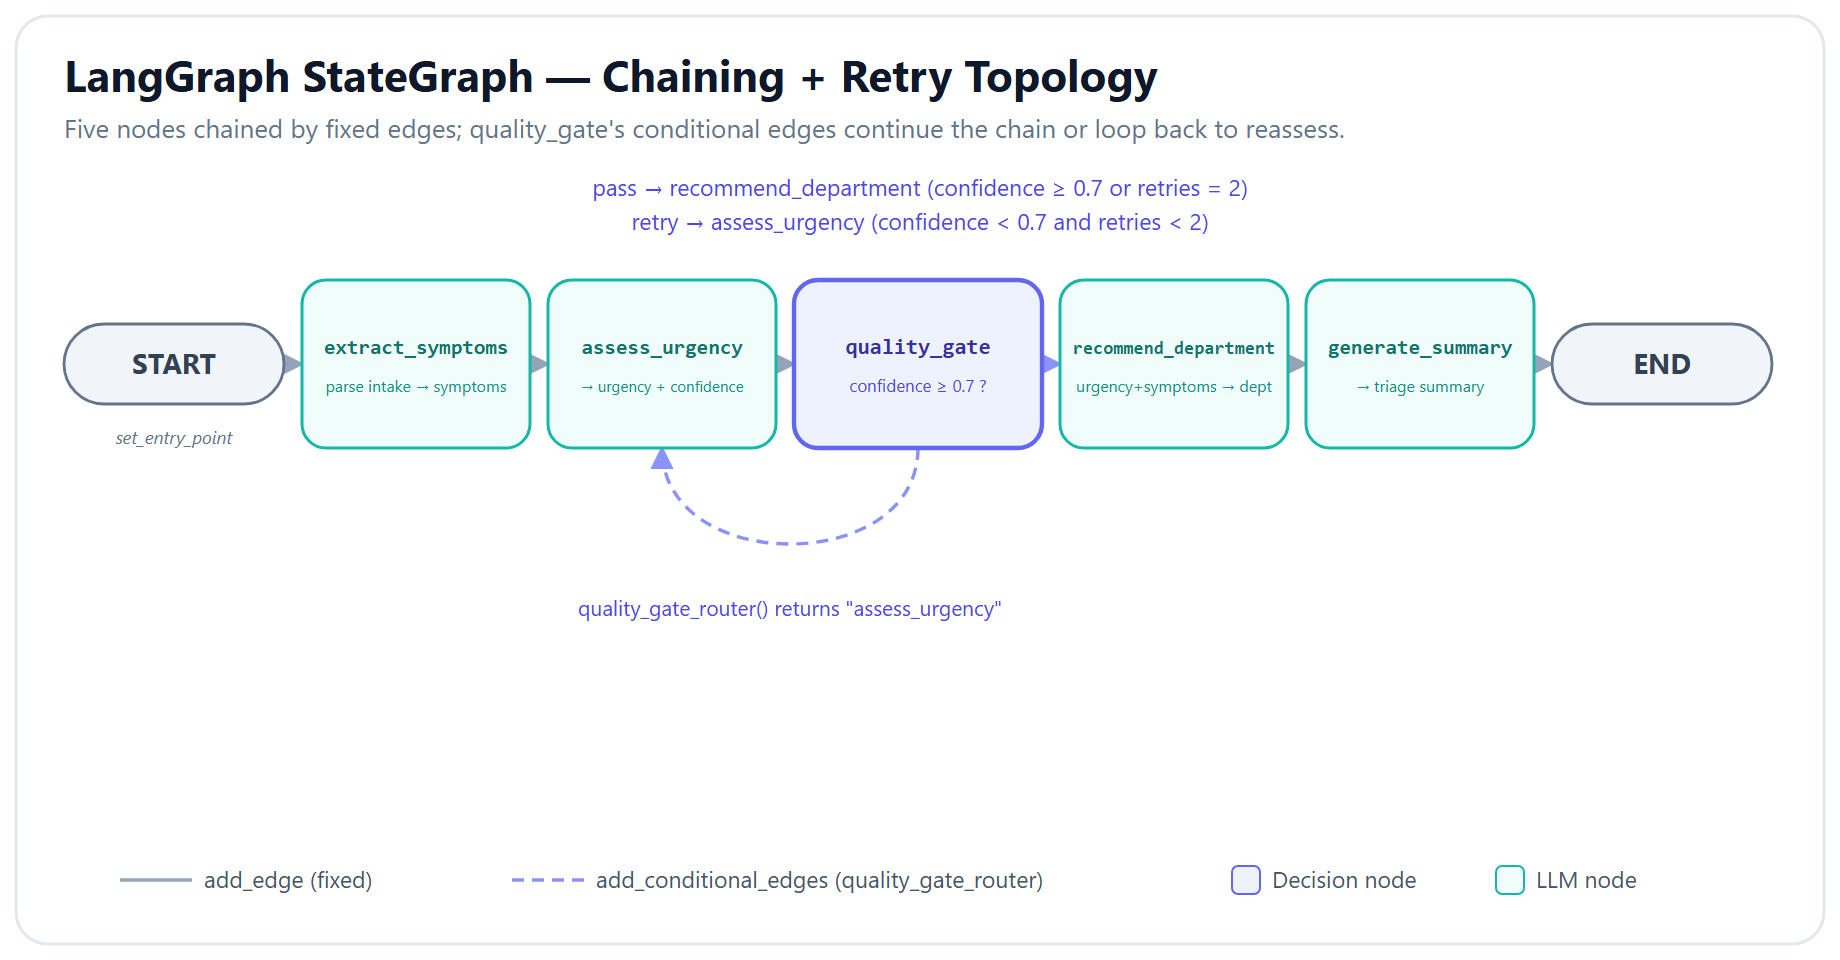

**Figure — LangGraph StateGraph topology.** Five nodes chained by fixed edges (`add_edge`); `quality_gate`'s conditional edges (`add_conditional_edges`) either continue to `recommend_department` or loop back to `assess_urgency` for a retry.

In [17]:
# ------------------------------------------------------------------
# Build the StateGraph step by step
# ------------------------------------------------------------------

# Step 1: Create the graph builder
builder = StateGraph(AgentState)

# Step 2: Add all nodes
builder.add_node("extract_symptoms", extract_symptoms)
builder.add_node("assess_urgency", assess_urgency)
builder.add_node("quality_gate", quality_gate)
builder.add_node("recommend_department", recommend_department)
builder.add_node("generate_summary", generate_summary)

# Step 3: Set entry point
builder.set_entry_point("extract_symptoms")

# Step 4: Add edges -- linear chain
builder.add_edge("extract_symptoms", "assess_urgency")
builder.add_edge("assess_urgency", "quality_gate")

# Step 5: Add conditional edge from quality_gate
builder.add_conditional_edges(
    "quality_gate",
    quality_gate_router,
    {
        "recommend_department": "recommend_department",
        "assess_urgency": "assess_urgency",
    },
)

# Step 6: Add remaining edges
builder.add_edge("recommend_department", "generate_summary")
builder.add_edge("generate_summary", END)

# Step 7: Compile
graph = builder.compile()

print("Graph compiled successfully!")
print(f"Nodes: {list(graph.nodes.keys())}")

Graph compiled successfully!
Nodes: ['__start__', 'extract_symptoms', 'assess_urgency', 'quality_gate', 'recommend_department', 'generate_summary']


## 9. Visualise the Graph

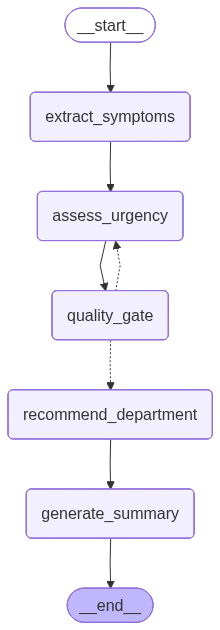

In [18]:
# ------------------------------------------------------------------
# Display the graph as a Mermaid diagram (works in Colab)
# ------------------------------------------------------------------
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

## 10. Helper Function to Run the Pipeline

A convenience function that creates the initial state from a patient dict and invokes
the graph, printing a trace of each step.

In [20]:
# ------------------------------------------------------------------
# Helper: run one patient through the full pipeline
# ------------------------------------------------------------------

def run_triage(patient: dict) -> dict:
    """Run a single patient through the triage pipeline and print the trace."""
    print("=" * 70)
    print(f"PROCESSING: {patient['patient_id']} -- {patient['patient_name']}, age {patient['patient_age']}")
    print("=" * 70)

    # Build initial state
    initial_state = {
        "patient_id": patient["patient_id"],
        "patient_name": patient["patient_name"],
        "patient_age": patient["patient_age"],
        "intake_description": patient["intake_description"],
        "extracted_symptoms": "",
        "urgency_level": "",
        "urgency_confidence": 0.0,
        "recommended_department": "",
        "triage_summary": "",
        "retry_count": 0,
    }

    # Stream through the graph to see each step
    final_state = None
    for step in graph.stream(initial_state):
        for node_name, node_output in step.items():
            node_output = node_output or {}  # Handle NoneType safely
            print(f"\n--- Step: {node_name} ---")
            if node_name == "extract_symptoms":
                print(node_output.get("extracted_symptoms", ""))
            elif node_name == "assess_urgency":
                print(f"Urgency: {node_output.get('urgency_level', 'N/A')}")
                print(f"Confidence: {node_output.get('urgency_confidence', 'N/A')}")
            elif node_name == "quality_gate":
                if node_output.get("retry_count"):
                    print(f"Retry count updated to: {node_output['retry_count']}")
                else:
                    print("Passed -- proceeding to department recommendation.")
            elif node_name == "recommend_department":
                print(f"Department: {node_output.get('recommended_department', 'N/A')}")
            elif node_name == "generate_summary":
                print(node_output.get("triage_summary", ""))
            final_state = node_output

    print("\n" + "=" * 70)
    print("PIPELINE COMPLETE")
    print("=" * 70 + "\n")
    return final_state


---

## 11. Test Run 1: Emergency Case (APL-001 -- Chest Pain)

This patient has classic cardiac emergency symptoms. Expected:
- Urgency: **emergency** with **high confidence**
- Department: **Cardiology** or **Emergency**
- Quality gate: should **pass on first try**

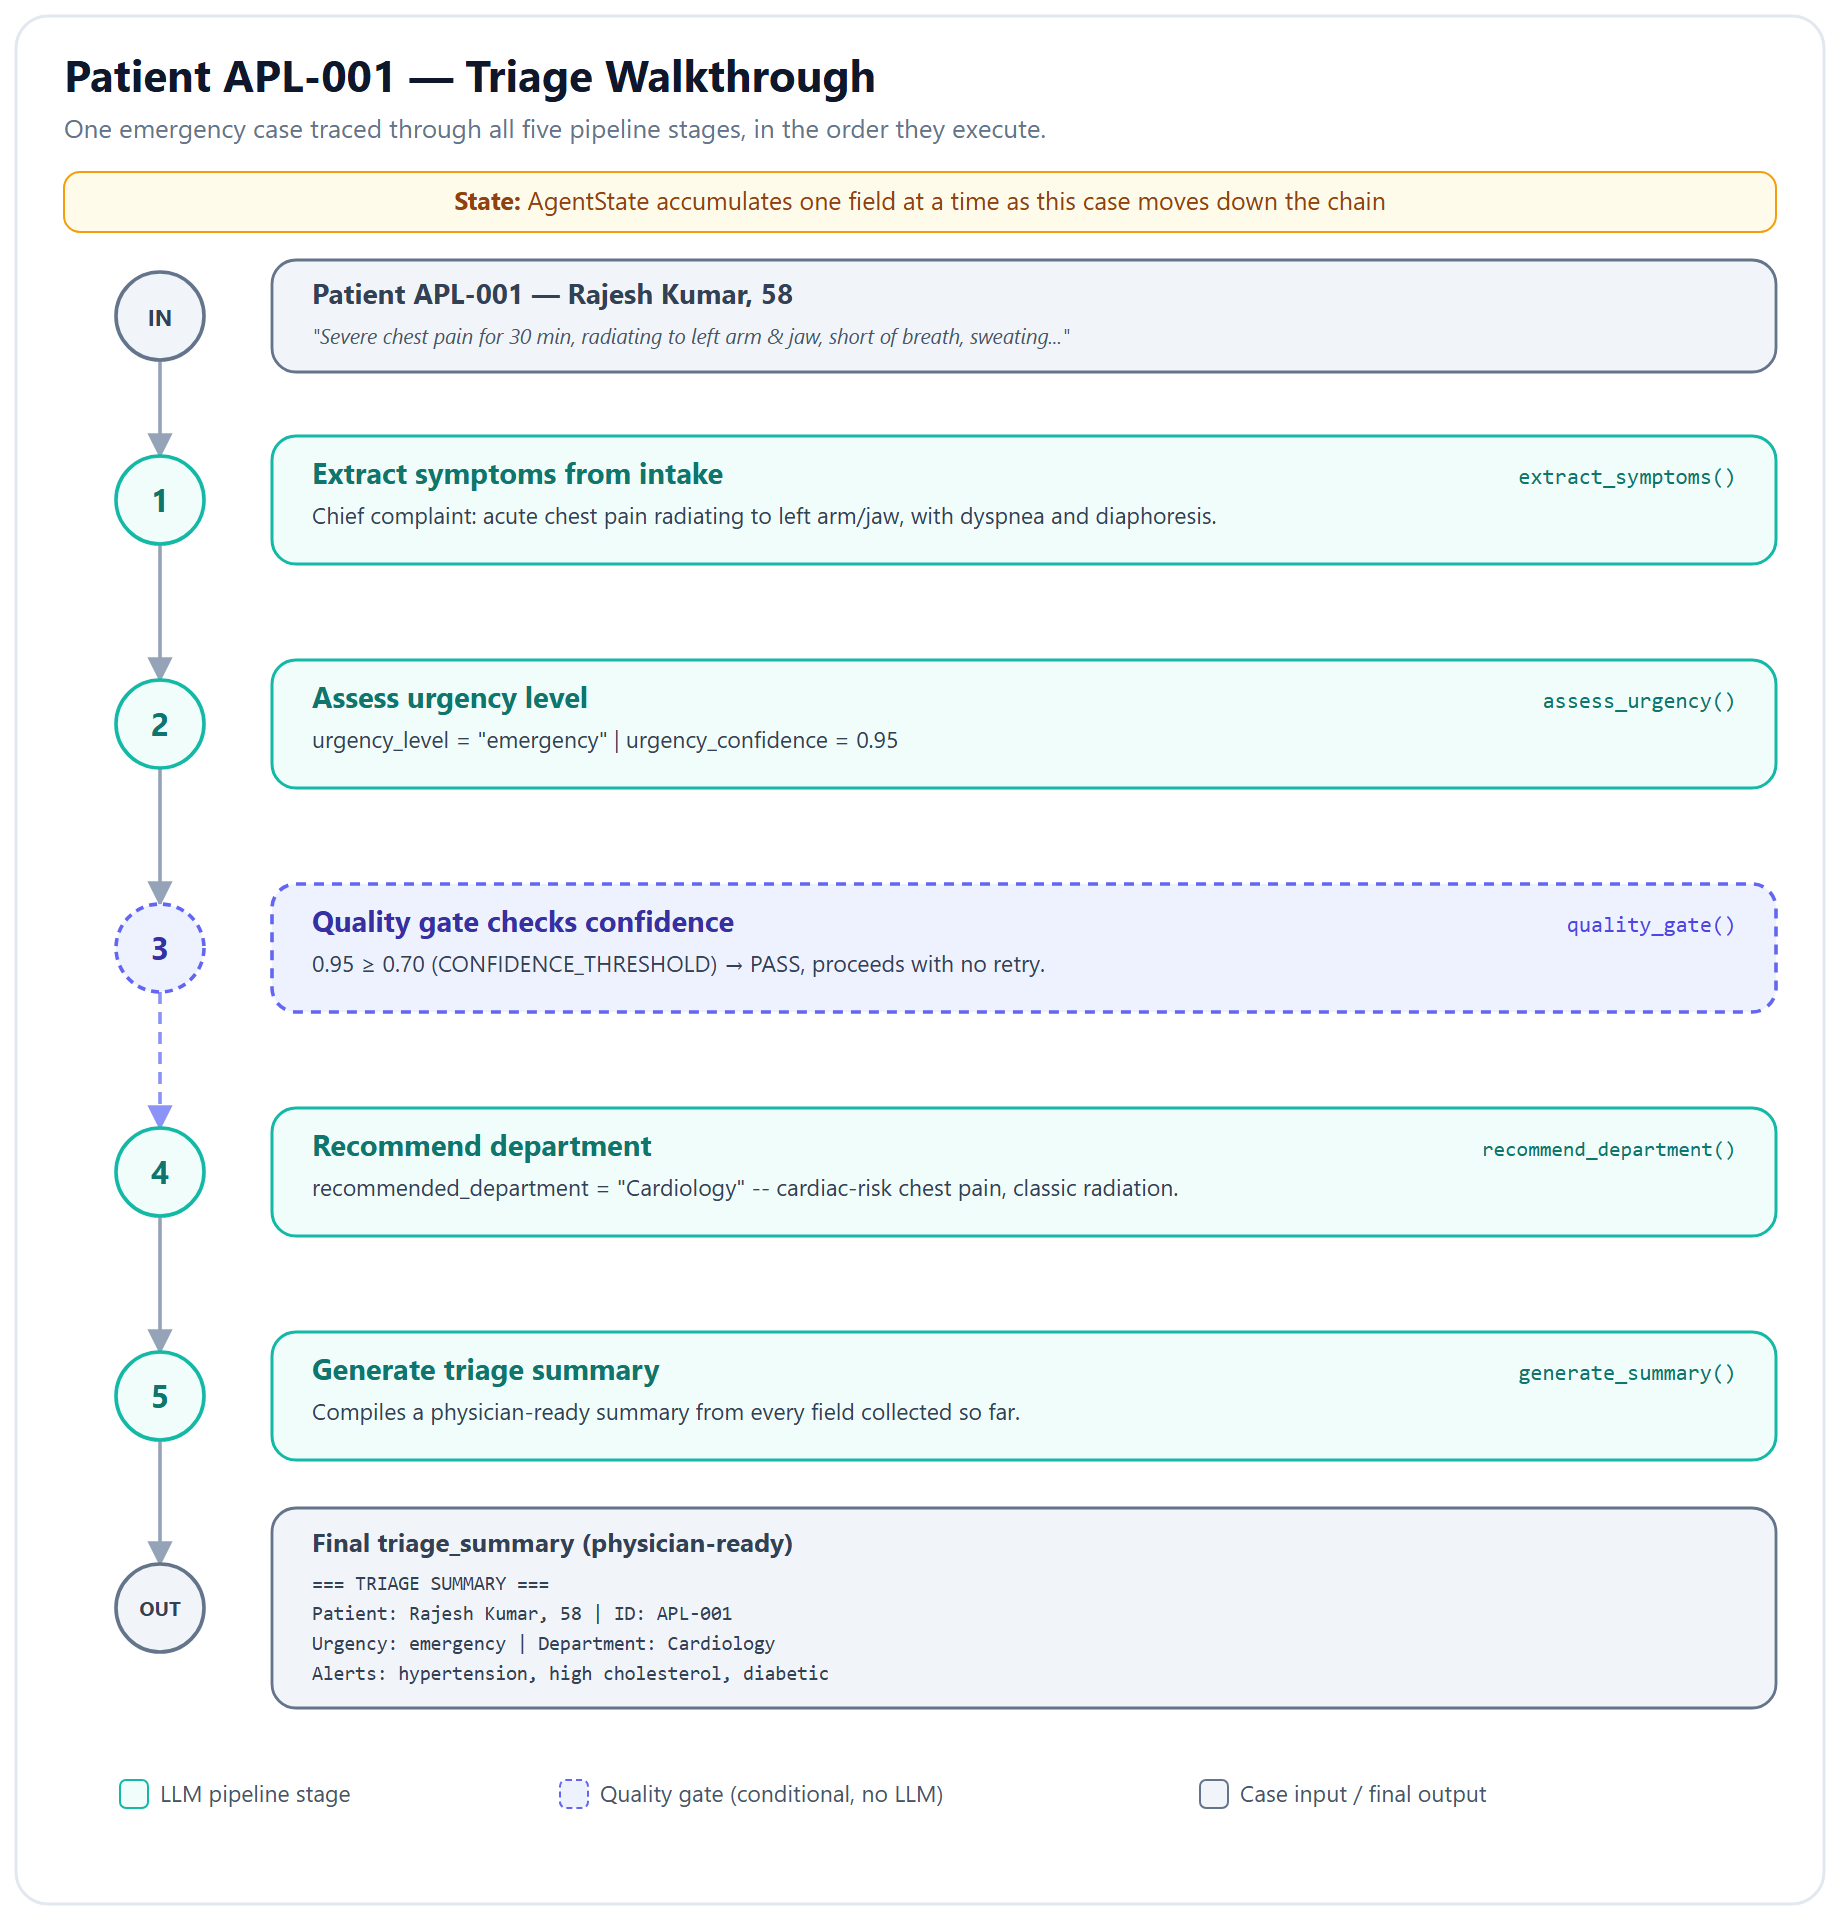

**Figure — Patient APL-001, start to finish.** A chest-pain emergency case traced through all five stages, from the raw intake form to a physician-ready `triage_summary`, with `quality_gate` passing on the first try at 0.95 confidence.

In [ ]:
# ------------------------------------------------------------------
# Test Run 1: APL-001 (Chest pain -- emergency)
# ------------------------------------------------------------------

result_patient_1 = run_triage(PATIENTS[0])

PROCESSING: APL-001 -- Rajesh Kumar, age 58

--- Step: extract_symptoms ---
CHIEF COMPLAINT: Severe chest pain for the last 30 minutes  
SYMPTOMS:  
- Severe chest pain radiating to left arm and jaw  
- Sudden onset during physical activity (climbing stairs)  
- Shortness of breath  
- Profuse sweating  
MEDICAL HISTORY: High blood pressure, high cholesterol, diabetes  
CUR

--- Step: assess_urgency ---
Urgency: emergency
Confidence: 0.95
  [GATE] PASS -- confidence 0.95 >= 0.7

--- Step: quality_gate ---
Passed -- proceeding to department recommendation.

--- Step: recommend_department ---
Department: Emergency

--- Step: generate_summary ---
=== TRIAGE SUMMARY ===  
Patient: Rajesh Kumar, 58 years  
ID: APL-001  
Chief Complaint: Severe chest pain for the last 30 minutes  
Key Findings:  
- Severe chest pain radiating to left arm and jaw  
- Sudden onset during physical activity (climbing stairs)  
- Shortness of breath  
- Profuse sweating  
- History of hypertension, hypercholester

## 12. Test Run 2: Ambiguous Case (APL-009 -- Fatigue/Dizziness)

This patient has vague symptoms (fatigue, dizziness for 2 weeks). Expected:
- Urgency: **standard** or **urgent** with **lower confidence**
- Quality gate: may **trigger a retry** because symptoms are non-specific
- Department: **General Medicine**

In [21]:
# ------------------------------------------------------------------
# Test Run 2: APL-009 (Fatigue/dizziness -- ambiguous)
# ------------------------------------------------------------------

result_patient_9 = run_triage(PATIENTS[8])

PROCESSING: APL-009 -- Anita Deshmukh, age 41

--- Step: extract_symptoms ---
CHIEF COMPLAINT: Persistent fatigue and dizziness for 2 weeks  
SYMPTOMS:  
- Feeling very tired for 2 weeks  
- Dizziness on standing up quickly  
- Occasional palpitations (fast heart beating)  
- Weakness  
- Normal appetite  
- No fever  
- Sleeping 8 hours but still exhausted  
MEDICAL HISTORY: None reported  
CURRENT MEDICATIONS: None reported  
ALLERGIES: None reported

--- Step: assess_urgency ---
Urgency: urgent
Confidence: 0.85
  [GATE] PASS -- confidence 0.85 >= 0.7

--- Step: quality_gate ---
Passed -- proceeding to department recommendation.

--- Step: recommend_department ---
Department: Cardiology

--- Step: generate_summary ---
=== TRIAGE SUMMARY ===  
Patient: Anita Deshmukh, 41 years  
ID: APL-009  
Chief Complaint: Persistent fatigue and dizziness for 2 weeks  
Key Findings:  
- Persistent fatigue lasting 2 weeks despite adequate sleep  
- Dizziness on standing (suggestive of orthostatic hy

## 13. Test Run 3: Routine Case (APL-007 -- Post-Surgery Follow-up)

This patient is here for a routine 2-week follow-up. Expected:
- Urgency: **routine** with **high confidence**
- Department: **Orthopedics**
- Quality gate: should **pass on first try**

In [22]:
# ------------------------------------------------------------------
# Test Run 3: APL-007 (Routine follow-up)
# ------------------------------------------------------------------

result_patient_7 = run_triage(PATIENTS[6])

PROCESSING: APL-007 -- Vikram Patel, age 52

--- Step: extract_symptoms ---
CHIEF COMPLAINT: 2-week post-surgery follow-up after right knee arthroscopic surgery  
SYMPTOMS:  
- Mild pain when walking (3/10)  
- Knee bending limited to about 90 degrees  
- Surgical wounds healing well, no redness or discharge  
MEDICAL HISTORY: Arthroscopic knee surgery on right knee 14 days ago  
CURRENT MEDICATIONS: Paracetamol 500mg as needed  
ALLERGIES: None reported

--- Step: assess_urgency ---
Urgency: routine
Confidence: 0.95
  [GATE] PASS -- confidence 0.95 >= 0.7

--- Step: quality_gate ---
Passed -- proceeding to department recommendation.

--- Step: recommend_department ---
Department: Orthopedics

--- Step: generate_summary ---
=== TRIAGE SUMMARY ===  
Patient: Vikram Patel, 52 years  
ID: APL-007  
Chief Complaint: 2-week post-operative follow-up after right knee arthroscopic surgery  
Key Findings:  
- Mild pain on walking (3/10)  
- Knee flexion limited to approximately 90 degrees  
- S

---

## 14. Run All 10 Patients -- Summary Table

Process every patient through the pipeline and display a compact summary.

In [23]:
# ------------------------------------------------------------------
# Process all 10 patients and collect results
# ------------------------------------------------------------------

all_results = []

for patient in PATIENTS:
    initial_state = {
        "patient_id": patient["patient_id"],
        "patient_name": patient["patient_name"],
        "patient_age": patient["patient_age"],
        "intake_description": patient["intake_description"],
        "extracted_symptoms": "",
        "urgency_level": "",
        "urgency_confidence": 0.0,
        "recommended_department": "",
        "triage_summary": "",
        "retry_count": 0,
    }
    final = graph.invoke(initial_state)
    all_results.append(final)
    print(f"  Done: {patient['patient_id']} -- {patient['patient_name']}")

print(f"\nAll {len(all_results)} patients processed.")

  [GATE] PASS -- confidence 0.95 >= 0.7
  Done: APL-001 -- Rajesh Kumar
  [GATE] PASS -- confidence 0.95 >= 0.7
  Done: APL-002 -- Priya Sharma
  [GATE] PASS -- confidence 0.90 >= 0.7
  Done: APL-003 -- Arjun Mehra
  [GATE] PASS -- confidence 0.95 >= 0.7
  Done: APL-004 -- Sunita Reddy
  [GATE] PASS -- confidence 0.85 >= 0.7
  Done: APL-005 -- Mohammed Farooq
  [GATE] PASS -- confidence 0.95 >= 0.7
  Done: APL-006 -- Kavitha Nair
  [GATE] PASS -- confidence 0.90 >= 0.7
  Done: APL-007 -- Vikram Patel
  [GATE] PASS -- confidence 0.90 >= 0.7
  Done: APL-008 -- Deepa Krishnan
  [GATE] PASS -- confidence 0.85 >= 0.7
  Done: APL-009 -- Anita Deshmukh
  [GATE] PASS -- confidence 0.80 >= 0.7
  Done: APL-010 -- Ravi Shankar

All 10 patients processed.


In [ ]:
# ------------------------------------------------------------------
# Print summary table
# ------------------------------------------------------------------

print(f"{'ID':<10s} {'Name':<22s} {'Age':>4s} {'Urgency':<12s} {'Conf':>6s} {'Retries':>8s} {'Department':<22s}")
print("-" * 90)
for r in all_results:
    print(
        f"{r['patient_id']:<10s} "
        f"{r['patient_name']:<22s} "
        f"{r['patient_age']:>4d} "
        f"{r['urgency_level']:<12s} "
        f"{r['urgency_confidence']:>6.2f} "
        f"{r['retry_count']:>8d} "
        f"{r['recommended_department']:<22s}"
    )

ID         Name                    Age Urgency        Conf  Retries Department            
------------------------------------------------------------------------------------------
APL-001    Rajesh Kumar             58 emergency      0.95        0 Emergency             
APL-002    Priya Sharma             32 emergency      0.95        0 Orthopedics           
APL-003    Arjun Mehra               4 urgent         0.90        0 Pediatrics            
APL-004    Sunita Reddy             45 emergency      0.95        0 Emergency             
APL-005    Mohammed Farooq          38 urgent         0.85        0 Gastroenterology      
APL-006    Kavitha Nair             27 emergency      0.95        0 Emergency             
APL-007    Vikram Patel             52 routine        0.95        0 Orthopedics           
APL-008    Deepa Krishnan           22 urgent         0.90        0 Orthopedics           
APL-009    Anita Deshmukh           41 urgent         0.85        0 Cardiology            

---

## 15. Conclusion & Next Steps

### What We Covered

| Concept | Key Takeaway |
|---------|-------------|
| **Prompt Chaining** | Each LLM call produces structured output that feeds the next step |
| **Quality Gate** | A confidence-threshold check prevents low-certainty results from propagating |
| **Conditional Retry** | When confidence is below 0.7, the pipeline loops back with extra context |
| **ChatPromptTemplate + LCEL** | `prompt \| llm` pattern keeps each step clean and composable |
| **StateGraph** | LangGraph manages the flow, including the conditional loop |

### Design Decisions

1. **Why a quality gate instead of just accepting the result?** -- In healthcare, a wrong
   urgency call can delay life-saving treatment. The quality gate forces the LLM to
   reconsider when it is unsure, with additional prompting to consider worst-case scenarios.

2. **Why max 2 retries?** -- Diminishing returns. If the LLM cannot decide after 3 total
   attempts (1 original + 2 retries), the symptoms are genuinely ambiguous and a human
   physician review is needed.

3. **Why separate node functions?** -- Each function is independently testable (as we
   demonstrated above) and can be swapped out without affecting the rest of the pipeline.

### Next Lab

In **Lab 2.5**, we explore the **Parallelization (Fan-Out/Fan-In)** pattern where multiple
checks run simultaneously instead of sequentially.